In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from functools import reduce
import matplotlib.pyplot as plt

plt.rcParams.update({
  "font.size": 9,
  "axes.titlesize": 9,
  "axes.labelsize": 9,
  "xtick.labelsize": 9,
  "ytick.labelsize": 9,
  "legend.fontsize": 9
})

# tTIS increases synaptic recruitment without strongly biasing plasticity direction

In [2]:
def p_to_stars(p):
  if p < 1e-4:
    return "****"
  elif p < 1e-3:
    return "***"
  elif p < 1e-2:
    return "**"
  elif p < 0.05:
    return "*"
  else:
    return "ns"

In [3]:
def expand_time(weights, time_step = 0.025, sample_time_step = 0.5, max_time = None):
  synapse_cols = [ f"Synapse{id}" for id in range(0, 10) ]
  time = weights.Time
  weights_to_update = weights.copy()[ synapse_cols ]

  if max_time is None:
    max_time = time.max()

  time = (time / time_step).round() * time_step
  weights_to_update.index = time

  new_time = np.arange(0, max_time + time_step, time_step)
  new_weights = pd.DataFrame(weights_to_update).set_index(time).reindex(new_time, method = "ffill")

  if time_step == sample_time_step:
    return new_weights

  # sample every sample_time_step
  sampled_time = np.arange(0, max_time, sample_time_step)
  new_weights = new_weights.loc[sampled_time]

  return new_weights

In [4]:
def read_weights(stimulation):
  cell_ids = np.arange(0, 20)
  frequency = 5

  weights = []
  for cell_id in cell_ids:
    filename = f"output/temporal-interference-1/{cell_id}/random_poisson/{frequency}/{stimulation}/synapse_weights.csv"
    synapse_weights = pd.read_csv(filename, index_col = 0)
    synapse_weights = expand_time(synapse_weights, time_step = 0.025, sample_time_step = 0.025, max_time = 10_000)

    synapse_columns = [ f"Synapse{id}" for id in range(0, 10) ]
    synapse_weights = synapse_weights.rename(columns = { synapse: f"{synapse}_cell{cell_id}" for synapse in synapse_columns })

    weights.append(synapse_weights)
  
  weights = reduce(lambda left, right: pd.merge(left, right, on = "Time", how = "inner"), weights)

  return weights

In [5]:
carrier = 1000
beat = 5
frequency = 5
synapse_cols = [f"Synapse{idx}" for idx in range(0, 10)]

stimulations = [
  "No tTIS",
  "50% tTIS",
  "90% tTIS"
]

colors = {
  "No tTIS": "#0D0887",
  "50% tTIS": "#E16462",
  "90% tTIS": "#B12A90"
}

weights = {
  "No tTIS": read_weights("noTI_0.1"),
  "50% tTIS": read_weights("1000_5_0.5_0.1"),
  "90% tTIS": read_weights("1000_5_0.9_0.1")
}

## 1. Fraction of LTP / LTD synapses

In [6]:
def categorize(w, atol = 1e-4):
  if w > 0.1 + atol: return "LTP"
  if w < 0.1 - atol: return "LTD"
  return "Stable"

order = ["LTP", "Stable", "LTD"]

In [7]:
weight_categories = []

for stimulation in weights.keys():
  w = weights[stimulation]
  
  time_select = np.where(w.index >= 9.5 * 1000)[0]
  final_weights = w.iloc[ time_select ].mean(axis = 0).tolist()

  categories = pd.DataFrame({
    "Stimulation": stimulation,
    "Weight": final_weights,
    "SynapseID": w.columns,
    "Category": [ categorize(w_) for w_ in final_weights ]
  })

  categories["Category"] = pd.Categorical(categories["Category"], categories = order, ordered = True)

  weight_categories.append(categories)

weight_categories = pd.concat(weight_categories, ignore_index = True)
weight_categories

,Stimulation,Weight,SynapseID,Category
0,No tTIS,0.199465,Synapse0_cell0,LTP
1,No tTIS,0.452394,Synapse1_cell0,LTP
2,No tTIS,0.080258,Synapse2_cell0,LTD
3,No tTIS,0.761628,Synapse3_cell0,LTP
4,No tTIS,0.468787,Synapse4_cell0,LTP
...,...,...,...,...
595,90% tTIS,0.313560,Synapse5_cell19,LTP
596,90% tTIS,0.337276,Synapse6_cell19,LTP
597,90% tTIS,0.412360,Synapse7_cell19,LTP
598,90% tTIS,0.999309,Synapse8_cell19,LTP


In [8]:
def format_ax(ax, grid = True):
  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)

  for spine in ax.spines.values():
    spine.set_color("gray")

  ax.tick_params(axis="both", colors="#1a1a1a")

  if grid:
    ax.grid(alpha = 0.5, zorder = 0)

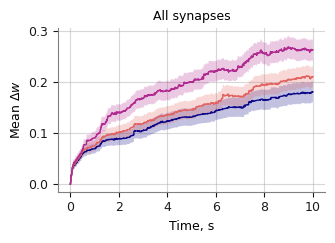

In [9]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (3.5, 2.5))

ax = axs
for stimulation in weights.keys():
  w = np.abs(weights[stimulation] - 0.1)

  time = w.index / 1000
  mean = np.mean(w, axis = 1)
  error = w.std(axis = 1) / np.sqrt(w.shape[1])

  ax.plot(
    time,
    mean,
    color = colors[stimulation],
    linewidth = 1,
    zorder = 5
  )

  ax.fill_between(
    time,
    mean - error,
    mean + error,
    color = colors[stimulation],
    alpha = 0.25,
    edgecolor = None,
    zorder = 2
  )

ax.set_ylabel(rf"Mean $\Delta w$")
ax.set_xlabel("Time, s")

ax.set_title("All synapses")

format_ax(ax)

plt.tight_layout()
plt.show()

No tTIS
11
50% tTIS
11
90% tTIS
11


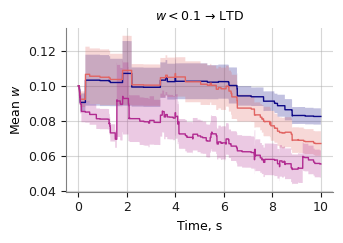

In [10]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (3.5, 2.5))

ax = axs
for stimulation in weights.keys():
  w = weights[stimulation]

  synapses = list(
    set(weight_categories[(weight_categories.Category == "LTD") & (weight_categories.Stimulation == "90% tTIS")].SynapseID) &
    set(weight_categories[(weight_categories.Category == "LTD") & (weight_categories.Stimulation == "50% tTIS")].SynapseID) &
    set(weight_categories[(weight_categories.Category == "LTD") & (weight_categories.Stimulation == "No tTIS")].SynapseID)
  )
  w = w[synapses]

  print(stimulation)
  print(len(synapses))

  time = w.index / 1000
  mean = np.mean(w, axis = 1)
  error = w.std(axis = 1) / np.sqrt(w.shape[1])

  ax.plot(
    time,
    mean,
    color = colors[stimulation],
    linewidth = 1,
    zorder = 5
  )

  ax.fill_between(
    time,
    mean - error,
    mean + error,
    color = colors[stimulation],
    alpha = 0.25,
    edgecolor = None,
    zorder = 2
  )

ax.set_ylabel(rf"Mean $w$")
ax.set_xlabel("Time, s")

ax.set_title(rf"$w < 0.1$ → LTD")

format_ax(ax)

# ax.set_ylim(0.055, 0.125)

plt.tight_layout()
plt.show()

No tTIS
83
50% tTIS
83
90% tTIS
83


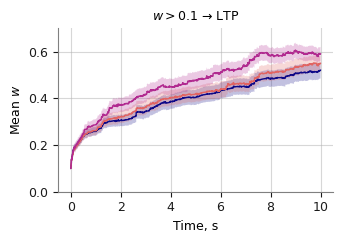

In [11]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (3.5, 2.5))

ax = axs
for stimulation in weights.keys():
  w = weights[stimulation]

  synapses = list(
    set(weight_categories[(weight_categories.Category == "LTP") & (weight_categories.Stimulation == "90% tTIS")].SynapseID) &
    set(weight_categories[(weight_categories.Category == "LTP") & (weight_categories.Stimulation == "50% tTIS")].SynapseID) &
    set(weight_categories[(weight_categories.Category == "LTP") & (weight_categories.Stimulation == "No tTIS")].SynapseID)
  )
  w = w[synapses]

  print(stimulation)
  print(len(synapses))

  time = w.index / 1000
  mean = np.mean(w, axis = 1)
  error = w.std(axis = 1) / np.sqrt(w.shape[1])

  ax.plot(
    time,
    mean,
    color = colors[stimulation],
    linewidth = 1,
    zorder = 5
  )

  ax.fill_between(
    time,
    mean - error,
    mean + error,
    color = colors[stimulation],
    alpha = 0.25,
    edgecolor = None,
    zorder = 2
  )

ax.set_ylabel(rf"Mean $w$")
ax.set_xlabel("Time, s")

ax.set_title(rf"$w > 0.1$ → LTP")

ax.set_ylim(0, 0.7)

format_ax(ax)

plt.tight_layout()
plt.show()

In [55]:
temp = weight_categories[ (weight_categories.Weight < 0.8) & (weight_categories.Category == "LTP") & (weight_categories.Stimulation != "50% tTIS") ]
print(round(temp[ temp.Stimulation == "No tTIS" ].Weight.mean(), 2))
print(round(temp[ temp.Stimulation == "No tTIS" ].Weight.std(), 2))
print(round(temp[ temp.Stimulation == "90% tTIS" ].Weight.mean(), 2))
print(round(temp[ temp.Stimulation == "90% tTIS" ].Weight.std(), 2))

temp["Stimulation"].value_counts()

0.32
0.19
0.36
0.19


Stimulation
90% tTIS    98
No tTIS     64
Name: count, dtype: int64

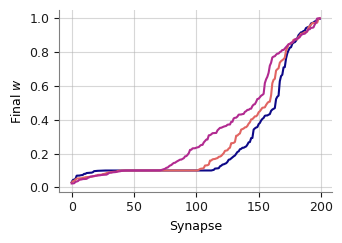

In [12]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (3.5, 2.5))

ax = axs
for stimulation in weight_categories.Stimulation.unique():
  w = weight_categories[ weight_categories.Stimulation == stimulation ].Weight.values
  ax.plot(
    np.sort(w),
    label = stimulation,
    color = colors[stimulation],
    linewidth = 1.5
  )

format_ax(ax)

ax.set_xlabel("Synapse")
ax.set_ylabel(rf"Final $w$")

plt.tight_layout()
plt.show()

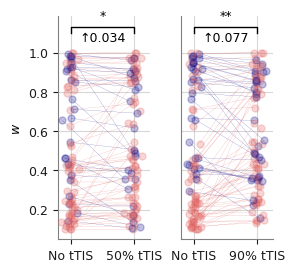

In [13]:
fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (3, 2.8), sharey = True)

type = "LTP"

for ax, stimulation in zip(axs, ["50% tTIS", "90% tTIS"]):
  # Intersection
  synapse_ids = list(
    set(weight_categories[(weight_categories.Category == type) & (weight_categories.Stimulation == stimulation)].SynapseID) &
    set(weight_categories[(weight_categories.Category == type) & (weight_categories.Stimulation == "No tTIS")].SynapseID)
  )

  w = weight_categories[ weight_categories["SynapseID"].isin(synapse_ids) ]

  y1 = w[ w.Stimulation == "No tTIS" ].set_index("SynapseID").loc[synapse_ids].reset_index()
  y2 = w[ w.Stimulation == stimulation ].set_index("SynapseID").loc[synapse_ids].reset_index()

  assert (y1.SynapseID.values == y2.SynapseID.values).all()

  y1 = y1.Weight.values
  y2 = y2.Weight.values

  x = [0, 1]
  jitter = 0.05
  x1 = np.random.normal(loc = 0, scale = jitter, size = len(y1))
  x2 = x1 + 1

  has_label_higher = False
  has_label_lower = False
  for i in range(len(y1)):
    if y1[i] > y2[i]:
      color = colors["No tTIS"]
      label = "" if has_label_higher else rf"$w_{{\text{{tTIS}}}} < w_{{\text{{no tTIS}}}}$"
      has_label_higher = True
    else:
      color = colors["50% tTIS"]
      label = "" if has_label_lower else rf"$w_{{\text{{tTIS}}}} > w_{{\text{{no tTIS}}}}$"
      has_label_lower = True

    points_x = [ x1[i], x2[i] ]
    points_y = [ y1[i], y2[i] ]

    ax.plot(points_x, points_y, color = color, linewidth = 0.1, alpha = 1, zorder = 5)

    ax.scatter(points_x, points_y, color = color, s = 25, alpha = 0.25, zorder = 10, label = label)
    
  ax.set_xticks(x, ["No tTIS", stimulation])
  ax.set_ylabel(rf"$w$")
  ax.set_xlim(-0.2, 1.25)

  if type == "LTD":
    ax.set_ylim(0, 0.122)

  format_ax(ax)

  # Add test statistics
  stat, p = stats.wilcoxon(y1, y2)
  stars = p_to_stars(p)

  y_max = max(np.max(y1), np.max(y2))
  
  y = y_max * 1.1

  ax.plot([0, 0, 1, 1], [y, y * 1.03, y * 1.03, y], color="black", linewidth=1)
  ax.text(0.5, y * 1.05, stars, ha="center", va="bottom", fontsize=9)

  symbol = "↑" if type == "LTP" else "↓"
  diff = np.mean(y2 - y1)
  text = f"{symbol}{diff:.2}"

  ax.text(0.5, y * 0.95, text, ha="center", va="bottom", fontsize=9)

axs[1].set_ylabel("")
axs[1].tick_params(left = False)

plt.tight_layout()
plt.show()

In [14]:
legend = axs[1].legend(
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    frameon=False,
    ncol=len(axs[1].get_legend_handles_labels()[0])  # make horizontal
)

handles, labels = axs[1].get_legend_handles_labels()

fig_leg = plt.figure(figsize=(4, 1))  # wider, shorter
fig_leg.legend(
    handles,
    labels,
    loc="center",
    frameon=False,
    ncol=len(handles)  # horizontal layout
)

fig_leg.savefig("legend.png", bbox_inches="tight", dpi=300)
plt.close(fig_leg)

In [15]:
stimulation = "90% tTIS"
no_ti = weight_categories[ weight_categories.Stimulation == "No tTIS" ].Category.values
ti = weight_categories[ weight_categories.Stimulation == stimulation ].Category.values

transition = pd.crosstab(no_ti, ti)

transition

col_0,LTP,Stable,LTD
row_0,,,
LTP,87,0,3
Stable,31,26,28
LTD,12,0,13


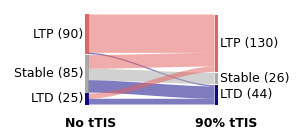

In [16]:
from sankeyflow import Sankey

color_map = {
    "LTP": f"{colors['50% tTIS']}",
    "LTD": f"{colors['No tTIS']}",
    "Stable": "#AAAAAA"
}

nodes = [
  [ (f" {cat}", transition.loc[cat].sum(), {"color": color_map[cat]}) for cat in transition.index ],
  [ (f"{cat}", transition[cat].sum(), {"color": color_map[cat]}) for cat in transition.columns ]
]

flows = []

for src in transition.index:
  for tgt in transition.columns:
    value = transition.loc[src, tgt]
    if value > 0:
      flows.append((
        f" {src}",
        f"{tgt}",
        value,
        {"color": f"{color_map[tgt]}88"}
      ))

plt.figure(figsize = (3, 1.5))
sankey = Sankey(
  nodes = nodes,
  flows = flows,
  node_opts = {
    "label_format": "{label} ({value:.0f})",
    "label_opts": {
      "fontsize": 9
    }
  }
)

sankey.draw()

ax = plt.gca()

for text in ax.texts:
  x, y = text.get_position()
  if x > 0.9:
    text.set_x(x + 0.05)
    text.set_ha("left")

ax.text(
  -0.15, -0.25,
  "No tTIS",
  fontweight = "semibold"
)

ax.text(
  1 - 0.15, -0.25,
  stimulation,
  fontweight = "semibold"
)

plt.tight_layout()
plt.show()

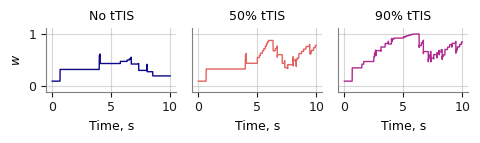

In [17]:
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize = (5, 1.5), sharey = True)

# ax = axs
for ax, stimulation in zip(axs, weights.keys()):
  w = weights[stimulation]

  synapses = weight_categories[ (weight_categories.Stimulation == stimulation) & (weight_categories.Category == "LTP") ].SynapseID.values[0]
  w = w[synapses]

  time = w.index / 1000
  # mean = np.mean(w, axis = 1)
  # error = w.std(axis = 1) / np.sqrt(w.shape[1])

  ax.plot(
    time,
    w,
    color = colors[stimulation],
    linewidth = 1,
    zorder = 5
  )

  # ax.fill_between(
  #   time,
  #   mean - error,
  #   mean + error,
  #   color = colors[stimulation],
  #   alpha = 0.25,
  #   edgecolor = None,
  #   zorder = 2
  # )

  ax.set_ylabel(rf"$w$")
  ax.set_xlabel("Time, s")

  ax.set_title(stimulation)

  ax.set_ylim(-0.1, 1.1)

  format_ax(ax)

for ax in axs[1:3]:
  ax.tick_params(left = None, labelleft = None)
  ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [18]:
correlation = []
for stimulation in ["50% tTIS", "90% tTIS"]:
  for synapse in weights["No tTIS"].columns:
    no_ti = weights["No tTIS"][synapse].values
    ti = weights[stimulation][synapse].values

    correlation.append(pd.DataFrame({
      "Correlation": np.corrcoef(no_ti, ti)[0, 1],
      "Synapse": [synapse],
      "Stimulation": stimulation
    }))

correlation = pd.concat(correlation, ignore_index = True)

50% tTIS
0.7008231861026417
90% tTIS
0.4209448877208314


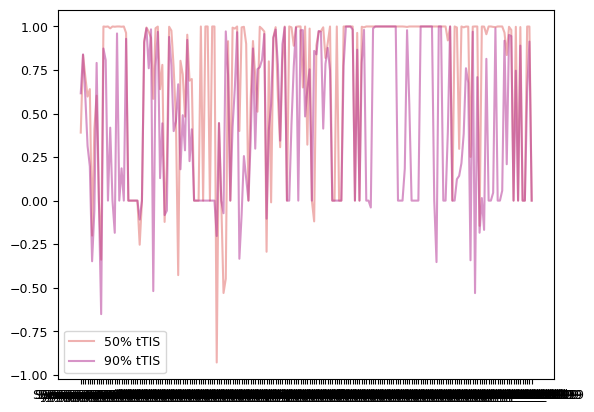

In [19]:
for stimulation in correlation.Stimulation.unique():
  corrs = correlation[ correlation.Stimulation == stimulation ]
  print(stimulation)
  print(corrs.Correlation.mean())

  plt.plot(
    corrs.Synapse,
    corrs.Correlation,
    color = colors[stimulation],
    label = stimulation,
    alpha = 0.5
  )

plt.legend()
plt.show()

In [23]:
mean_weights = {}
for stimulation in weights.keys():
  mean = np.abs(weights[stimulation] - 0.1).mean(axis = 1)
  time = weights[stimulation].index / 1000

  mean_weights[stimulation] = pd.DataFrame({
    "Time": time,
    "Mean": mean
  })

from scipy.optimize import curve_fit

def rising_double_exp(t, a1, tau1, a2, tau2):
  w0 = 0
  t0 = 0 # starting time is zero

  return w0 + a1 * (1 - np.exp(-(t - t0) / tau1)) + a2 * (1 - np.exp(-(t - t0) / tau2))

def rising_exp(t, a1, tau1):
  w0 = 0
  t0 = 0 # starting time is zero

  return w0 + a1 * (1 - np.exp(-(t - t0) / tau1))

def fit_double_exponential(weights, time):
  t = np.array(time)

  popt, _ = curve_fit(
    f = rising_double_exp,
    xdata = t,
    ydata = weights,
    p0 = [0.1, 1.0, 0.1, 2.0],
    bounds = ([0, 1e-6, 0, 1e-6], [100, 10, 100, 10])
  )
  a1, tau1, a2, tau2 = popt

  # Swap for consistency: tau1 always lower than tau2
  a1, tau1, a2, tau2 = (a2, tau2, a1, tau1) if tau1 > tau2 else (a1, tau1, a2, tau2)

  return rising_double_exp(t, a1, tau1, a2, tau2), {
    "a1": a1, "tau1": tau1, "a2": a2, "tau2": tau2
  }

def fit_exponential(weights, time):
  t = np.array(time)
  
  amp_guess = weights.max() - weights.min()

  popt, _ = curve_fit(
    f = rising_exp,
    xdata = t,
    ydata = weights,
    p0 = [amp_guess, 1.0],
    bounds = ([0, 1e-6], [100, 600])
  )
  a1, tau1 = popt

  return rising_exp(t, a1, tau1), {
    "a1": a1, "tau1": tau1
  }



fit = []

for stimulation in mean_weights.keys():
  print(stimulation)
  means = mean_weights[stimulation]
  _, results = fit_double_exponential(means.Mean, means.Time)
  fit.append(pd.DataFrame({
    "Stimulation": [stimulation],
    "A": round(results["a1"], 2),
    "Tau": round(results["tau1"], 2),
    "A2": round(results["a2"], 2),
    "Tau2": round(results["tau2"], 2)
  }))
  
  print(results)

fit = pd.concat(fit, ignore_index = True)
fit

No tTIS
{'a1': 0.05352799650903958, 'tau1': 0.17746450189361165, 'a2': 0.1997179547100902, 'tau2': 9.825262849683915}
50% tTIS
{'a1': 0.05530664012139649, 'tau1': 0.17859469482396867, 'a2': 0.24482112810595227, 'tau2': 9.999999999999684}
90% tTIS
{'a1': 0.08765851952330471, 'tau1': 0.5458252201935576, 'a2': 0.28032193604954275, 'tau2': 9.31055084302331}


,Stimulation,A,Tau,A2,Tau2
0,No tTIS,0.05,0.18,0.20,9.83
1,50% tTIS,0.06,0.18,0.24,10.00
2,90% tTIS,0.09,0.55,0.28,9.31


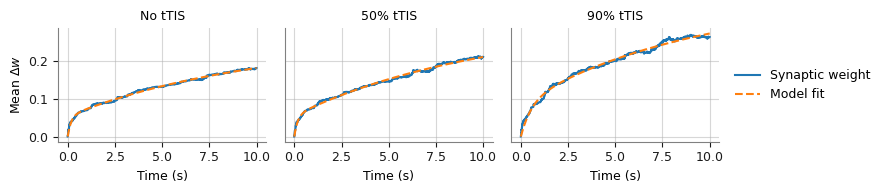

In [36]:
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize = (9, 2), sharey = True)

for ax, stimulation in zip(axs, mean_weights.keys()):
  means = mean_weights[stimulation]

  # fit model
  y_fit, results = fit_double_exponential(means["Mean"], means["Time"])

  t = np.array(means["Time"])
  t_shifted = t - t.min()

  # data
  ax.plot(t, means["Mean"], label = "Synaptic weight")

  # model
  ax.plot(t, y_fit, linestyle = "--", label = "Model fit")

  ax.set_xlabel("Time (s)")
  ax.set_ylabel(rf"Mean $\Delta w$")
  ax.set_title(stimulation)

  format_ax(ax)

ax.legend(
  bbox_to_anchor = (1.02, 0.5),
  loc = "center left",
  frameon = False
)

for ax in axs[1:3]:
  ax.set_ylabel("")
  ax.tick_params(left = None, labelleft = None)

plt.tight_layout()
plt.show()

In [34]:
table = fit.to_latex(index=False, float_format="%.2f", caption = "Table caption", label = "supplementary", position = "H")
print(table)

\begin{table}[H]
\caption{Table caption}
\label{supplementary}
\begin{tabular}{lrrrr}
\toprule
Stimulation & A & Tau & A2 & Tau2 \\
\midrule
No tTIS & 0.05 & 0.18 & 0.20 & 9.83 \\
50% tTIS & 0.06 & 0.18 & 0.24 & 10.00 \\
90% tTIS & 0.09 & 0.55 & 0.28 & 9.31 \\
\bottomrule
\end{tabular}
\end{table}

